In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('PowerGeneration - PowerGeneration (1).csv')
df.head()

,Dates,Power Station,Monitored Cap.(MW),Total Cap. Under Maintenace (MW),Planned Maintanence (MW),Forced Maintanence(MW),Other Reasons (MW),Programme or Expected(MU),Actual(MU),Excess(+) / Shortfall (-),Deviation
0,2017-09-01,Delhi,2235.4,135.00,0.00,135.0,0,13,18,5.00,0.0
1,2017-09-01,Haryana,2720.0,2470.00,0.00,2470.0,0,28,7,-21.80,0.0
2,2017-09-01,Himachal Pradesh,3378.0,379.00,0.00,231.0,0,40,46,5.63,0.0
3,2017-09-01,Jammu and Kashmir,1285.0,150.00,0.00,0.0,0,14,23,9.43,0.0
4,2017-09-01,Punjab,3826.3,2697.65,77.65,2620.0,0,39,17,-21.69,0.0


In [3]:
temp_df = df[df['Power Station'].isin(df['Power Station'].value_counts().head().index.to_list())]

Text(0, 0.5, 'Total Cap. Under Maintenace (MW)')

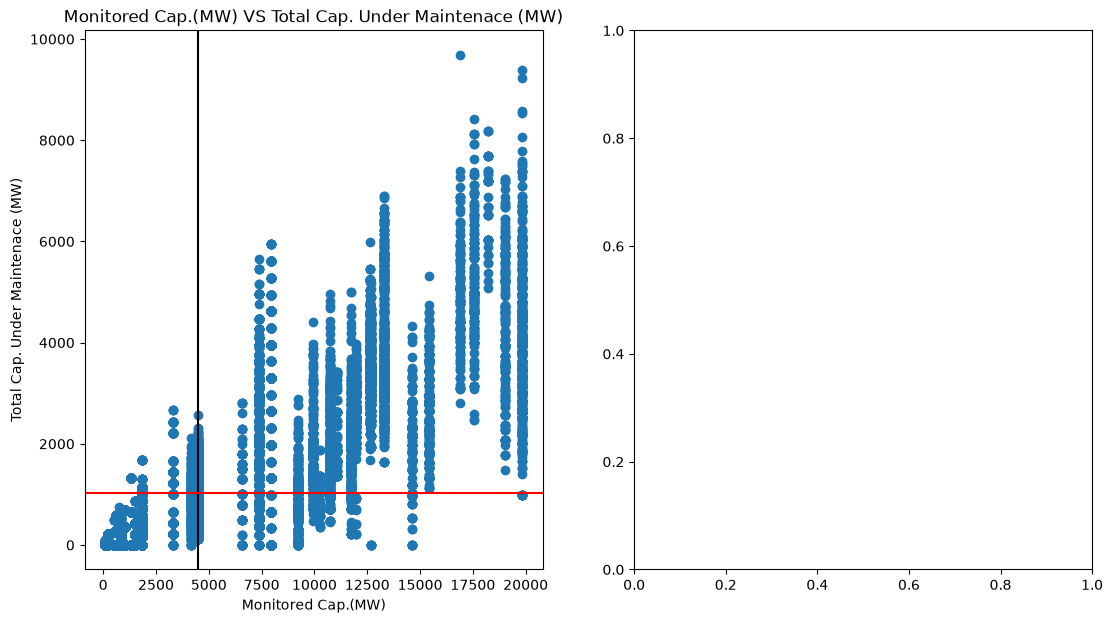

In [4]:
fig,ax = plt.subplots(nrows=1 , ncols=2,figsize=(13,7))
ax[0].scatter(temp_df['Monitored Cap.(MW)'] , [temp_df['Total Cap. Under Maintenace (MW)']])
ax[0].axvline(temp_df['Monitored Cap.(MW)'].mean(),color='black')
ax[0].axhline(temp_df['Total Cap. Under Maintenace (MW)'].mean(), color='red')
ax[0].set_title('Monitored Cap.(MW) VS Total Cap. Under Maintenace (MW)')
ax[0].set_xlabel('Monitored Cap.(MW)')
ax[0].set_ylabel('Total Cap. Under Maintenace (MW)')

### Problem-3: Make a 3D Surface plot of this below mathematical equation.
**z=|x|−|y|**

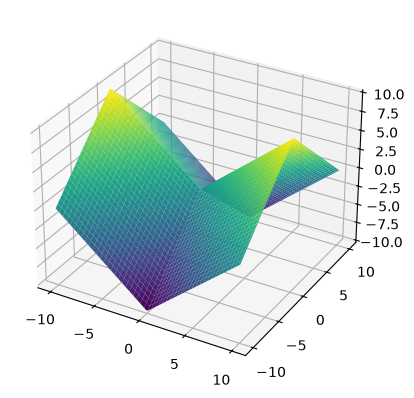

In [5]:
x = np.linspace(-10,10,100)
y = np.linspace(-10,10 ,100)
X,Y = np.meshgrid(x,y)
Z= abs(X) - abs(Y)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X,Y,Z , cmap='viridis')
plt.show()

**Draw a contour plot also for this**

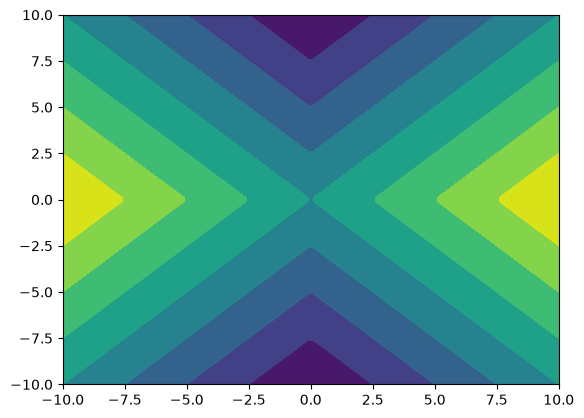

In [6]:
plt.contourf(X,Y,Z,cmap='viridis')

**Description of Dataset:**

* Date: It gives the date of which stocks details are given.
* Symbol: Name of stock
* Open: It gives the opening price of stock on that date.
* High: It gives the highest price to which the stock ascened on that day.
* Low: It gives the highest price to which the stock plummeted on that day.
* Close: It gives the closing price of stock on that date.
* Volume: It gives the amount of stock traded on that date.
* VWAP: The volume-weighted average price (VWAP) is a statistic used by traders to determine what the average price is based on both price and volume.
* Turnover: 

In [7]:
nifty = pd.read_csv('nifty-50 - nifty-50.csv')
nifty.sample(5)

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades
428427,2003-10-09,SESAGOA,EQ,288.75,289.0,305.40,289.00,298.40,297.60,298.80,253554,7.576093e+12,NaN
238213,2014-12-24,ITC,EQ,374.65,374.5,378.45,367.25,370.50,371.40,372.77,13749805,5.125569e+14,70348.0
24949,2014-12-10,WIPRO,EQ,556.90,556.0,559.25,551.40,551.50,552.15,554.26,1299523,7.202757e+13,18353.0
421264,2016-05-05,CIPLA,EQ,533.20,535.5,544.00,533.50,543.05,541.80,539.46,1025103,5.530043e+13,26732.0
61081,2015-05-27,HINDUNILVR,EQ,855.35,855.5,860.00,845.70,860.00,857.70,853.92,530542,4.530380e+13,19654.0


In [8]:
nifty.shape

(480996, 13)

#### Problem-6 Use Pandas plot functions
- Line plot of closing value of top 5 Stocks in Year 2020.
- Take top 5 stocks based on total turnover in Year 2020

In [9]:
nifty['Date'] = pd.to_datetime(nifty['Date'])

In [10]:
temp_df = nifty[nifty['Date'].dt.year == 2020]
top_5_in_2020 = temp_df.groupby('Symbol')['Turnover'].sum().sort_values(ascending=False).head().index.to_list()

In [11]:
temp_df = temp_df[temp_df['Symbol'].isin(top_5_in_2020)]
temp_df.sort_values('Date',inplace=True)

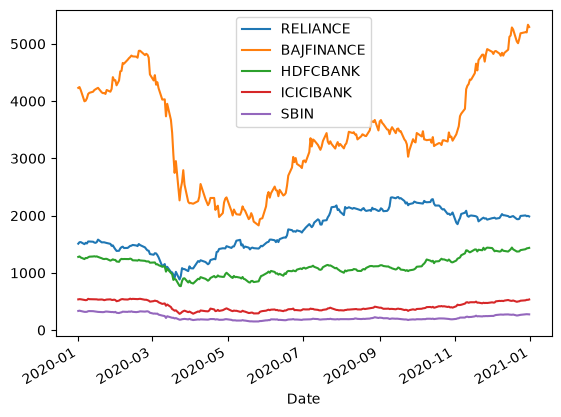

In [12]:
AX = temp_df[temp_df['Symbol'] == 'RELIANCE'].plot( x='Date' , y = 'Close', label='RELIANCE'  )
for company in top_5_in_2020[1:]:
  temp_df[temp_df['Symbol'] == company].plot( x='Date' , y = 'Close', label=company ,ax=AX)

### Problem-7 Scatter plot Close price vs Volume for TOP-5 Stocks in year 2021
#### Color on Symbol Column

In [13]:
nifty.head()

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades
0,2000-01-03,HDFCBANK,EQ,157.40,166.00,170.00,166.00,170.00,170.00,169.52,33259,5.638122e+11,NaN
1,2000-01-04,HDFCBANK,EQ,170.00,182.00,183.45,171.00,174.00,173.80,174.99,168710,2.952261e+12,NaN
2,2000-01-05,HDFCBANK,EQ,173.80,170.00,173.90,165.00,168.00,166.95,169.20,159820,2.704094e+12,NaN
3,2000-01-06,HDFCBANK,EQ,166.95,168.00,170.00,165.30,168.95,168.30,168.44,85026,1.432166e+12,NaN
4,2000-01-07,HDFCBANK,EQ,168.30,162.15,171.00,162.15,170.75,168.35,166.79,85144,1.420158e+12,NaN


In [15]:
temp_df = nifty[nifty['Date'].dt.year == 2021]
top_5_in_2021 = temp_df.groupby('Symbol')['Turnover'].sum().sort_values(ascending=False).head()

c:\Users\Lenovo\Desktop\Python\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


<Axes: xlabel='Close', ylabel='Volume'>

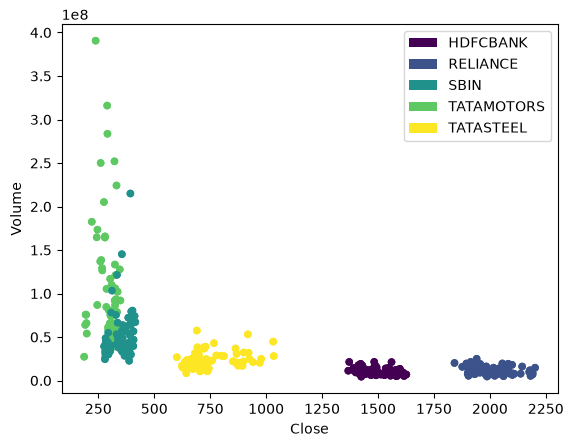

In [20]:
temp_df[temp_df['Symbol'].isin(top_5_in_2021.index.to_list())].plot(kind='scatter' ,x='Close',y='Volume' ,c='Symbol' , cmap='viridis')

### Problem-8 Create a 3-D Scatter Plot using time,x,y on below synthetic data. and give color gradiant on z


In [21]:
# Create a 3D dataset
time = np.linspace(0, 10, 100)
x = np.sin(time)
y = np.cos(time)
z = time

# Create a DataFrame from the dataset
data = pd.DataFrame({'time': time, 'x': x, 'y': y, 'z': z})
data

,time,x,y,z
0,0.00000,0.000000,1.000000,0.00000
1,0.10101,0.100838,0.994903,0.10101
2,0.20202,0.200649,0.979663,0.20202
3,0.30303,0.298414,0.954437,0.30303
4,0.40404,0.393137,0.919480,0.40404
...,...,...,...,...
95,9.59596,-0.170347,-0.985384,9.59596
96,9.69697,-0.268843,-0.963184,9.69697
97,9.79798,-0.364599,-0.931165,9.79798
98,9.89899,-0.456637,-0.889653,9.89899


Text(0.5, 0, 'y')

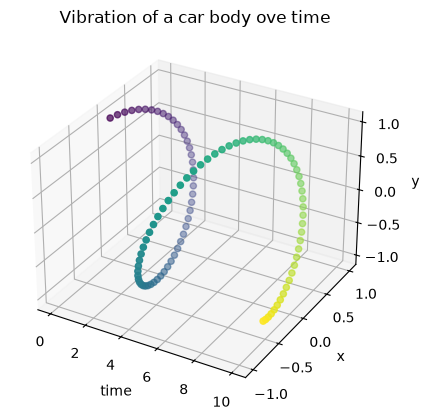

In [26]:
fig = plt.figure()
ax = fig.add_subplot(projection = '3d')
ax.scatter3D(data['time'] , data['x'] , data['y'] , c = data['z'])
ax.set_title('Vibration of a car body ove time')
ax.set_xlabel('time')
ax.set_ylabel('x')
ax.set_zlabel('y')

### `Problem 9:` Create a surface plot and the 2 types of the contour plots of the below equation.

$$z = sin(\sqrt{x^2 + y^2})$$

In [33]:
x = np.linspace(-10,10,100)
y = np.linspace(-10,10,100)
X,Y = np.meshgrid(x,y)
Z = np.sin(np.sqrt(X**2 + Y**2))

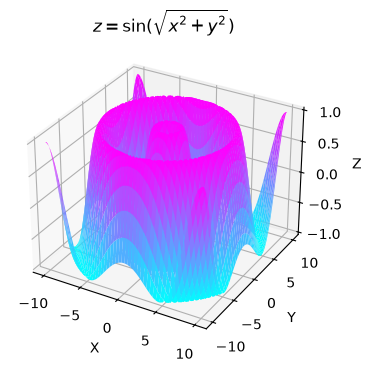

In [43]:
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(projection = '3d')
ax.plot_surface(X,Y,Z , cmap='cool')
ax.set_title(r'$z= \sin(\sqrt{x^2 + y^2})$')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()